## **Homework 2 Notebook - Marketing Analytics**  
## *Customer Lifetime Value (CLV) Analysis*  

---

**Author:** *Matteo Fumagalli*  
**Student ID:** *894468*  
**University:** *University of Milano-Bicocca*  
**Degree Program:** *Master’s Degree in Data Science*   
**Academic Year:** *2025/2026*

---

### **Notebook Description**
This notebook contains the complete data analysis pipeline used to transform raw customer data into actionable managerial insights.

All steps are fully reproducible from the files provided in this repository.

---

## **0 - Environment Setup**

In [1]:
# Library imports
import pandas as pd
pd.set_option('display.max_colwidth', None)

# Local imports (database)
from database.db import (
    get_connection, create_database, 
    execute_sql_file, insert_all_dataframes)

# Local imports (part A)
from data_preparation.data_understanding import (
    load_all_data, 
    define_table_summary, define_data_dictionary,
    analyse_missing_values, preprocess_missing_values,
    preprocess_date_time, preprocess_item_discount,
    check_price_timeline_anomalies,
    normalize_campaign_channels,
    display_summary_statistics, 
    check_duplicates
)

# Local imports (part B)
from data_preparation.exploratory_data_analysis import (
    plot_spending_distribution,
    plot_purchase_frequency_distribution,
    plot_revenue_per_category,
    plot_customer_segments_per_status,
    plot_revenue_concentration,
    plot_time_trends
)

# Local imports (part C)
from models.rfm import (
    get_rfm_customer_table,
    plot_continuous_rfm_metrics_distribution,
    plot_ordinal_rfm_metrics_distribution,
    compute_rfm_statistics_summary,
    get_top10_rfm_customer_table,
    compute_rfm_distribution_table, plot_rfm_score_distribution
)

# Local imports (part D)
from models.clv_analysis import(
    get_clv_customer_table, 
    plot_clv_distribution,
    plot_clv_distribution_per_status,
    plot_revenue_and_transactions,
    get_top20_clv_customer_table
)

# Local imports (part E)
from models.clv_prediction import (
    extract_transactions_data, split_calibration_holdout_df,
    train_predictive_models, evaluate_predictive_models,
    predict_clv_customer_table,
    plot_predicted_clv_distribution,
    plot_actual_and_predicted_spend,
    plot_frequency_recency,
    plot_probability_alive
)

# Local imports (part F)
from models.segmentation import (
    assign_segment, extract_customer_information,
    get_segment_summary,
    plot_segment_clv_distribution,
    plot_segment_clv_metrics,
    plot_segment_top_categories,
    plot_segment_customer_type
)

# Obtain database credentials
from config import DB_CONFIG

---

## **A - Data Understanding and Preparation**

In [2]:
# Load all CSV files
dataframes = load_all_data()

== DATAFRAMES LOADING ==
 -> DataFrame Category loaded successfully
 -> DataFrame Product loaded successfully
 -> DataFrame Price Change loaded successfully
 -> DataFrame Channel loaded successfully
 -> DataFrame Store loaded successfully
 -> DataFrame External Factor loaded successfully
 -> DataFrame Customer loaded successfully
 -> DataFrame Session loaded successfully
 -> DataFrame Support Ticket loaded successfully
 -> DataFrame Marketing Channel loaded successfully
 -> DataFrame Campaign Touch loaded successfully
 -> DataFrame Promotion loaded successfully
 -> DataFrame Order loaded successfully
 -> DataFrame Order Item loaded successfully

Successfully loaded all 14 DataFrames


In [3]:
# Display a brief description of each DataFrame
define_table_summary(dataframes)

== TABLE SUMMARY ==


,DataFrame Name,Records,Columns,Description
0,Category,10,2,Macro-classification of products
1,Product,200,4,Catalogue of available products with brand and SKU
2,Price change,1978,4,Weekly history of price updates per product
3,Channel,4,2,Sales channels for purchasing
4,Store,140,4,Physical retail locations and types
5,External factor,21840,10,Environmental and marketing conditions per store
6,Customer,10000,6,Customer base profiles
7,Session,1259647,7,Digital activity and online behaviour of customers
8,Support ticket,1600,7,Customer service logs with resolution and CSAT score
9,Marketing channel,12,4,Media platforms for advertising


In [4]:
# Inspect the type of each variable before preprocessing
define_data_dictionary(dataframes)

== DATA DICTIONARY - TABLE: CATEGORY ==


,Variable Name,Type,Unique Values
0,category_id,str,10
1,category_name,str,10




== DATA DICTIONARY - TABLE: PRODUCT ==


,Variable Name,Type,Unique Values
0,product_id,str,200
1,category_id,str,10
2,brand,str,27
3,sku_name,str,195




== DATA DICTIONARY - TABLE: PRICE CHANGE ==


...

,Variable Name,Type,Unique Values
0,promo_id,str,280
1,promo_type,str,3
2,start_date,str,248
3,end_date,str,249
4,discount_value,float64,15




== DATA DICTIONARY - TABLE: ORDER ==


,Variable Name,Type,Unique Values
0,order_id,str,356242
1,customer_id,str,9388
2,order_date,str,1092
3,store_id,str,140
4,channel_id,str,4
5,payment_type,str,5
6,year,int64,4
7,week,int64,52




== DATA DICTIONARY - TABLE: ORDER ITEM ==


,Variable Name,Type,Unique Values
0,order_item_id,str,1048575
1,order_id,str,333571
2,product_id,str,200
3,promo_id,str,280
4,quantity,int64,3
5,item_discount,float64,24583


In [5]:
# Analyse columns with missing values in each DataFrame
analyse_missing_values(dataframes)

== MISSING VALUES ==


,DataFrame Name,Column Name,Missing Values,Percentage (%)
0,order_item,promo_id,732376,69.84


In [6]:
# Preprocess data before inserting them into the database
dataframes = preprocess_missing_values(dataframes)
dataframes = preprocess_date_time(dataframes)
dataframes = preprocess_item_discount(dataframes)

== MISSING VALUES PREPROCESSING ==
 -> Successfully preprocessed column promo_id within DataFrame order_item

== DATE AND TIME PREPROCESSING ==
 -> Processed column signup_date within DataFrame customer
 -> Processed column factor_date within DataFrame external_factor
 -> Processed column created_date within DataFrame support_ticket
 -> Processed column touch_date within DataFrame campaign_touch
 -> Processed column start_date within DataFrame promotion
 -> Processed column end_date within DataFrame promotion
 -> Processed column order_date within DataFrame order
 -> Processed column session_start within DataFrame session

Successfully preprocessed date and time values

== ITEM DISCOUNT PREPROCESSING ==
 -> Successfully corrected 11972 rows where item_discount exceeded line revenue


In [7]:
# Detect products ordered before their first price is registered, as well as 
# products without a registered price
check_price_timeline_anomalies(dataframes)

== PRODUCT PRICE TIMELINE CHECK ==
 -> Found 26988 order rows with a price registered only after the order (2.57% of total transactions)


In [8]:
# Align campaign_touch channels to marketing_channel ids for database integrity
dataframes = normalize_campaign_channels(dataframes)

== DATABASE INTEGRITY PREPROCESSING ==
 -> Successfully aligned campaign_touch with marketing_channel


In [9]:
# Inspect the type of each variable after preprocessing
define_data_dictionary(dataframes)

== DATA DICTIONARY - TABLE: CATEGORY ==


,Variable Name,Type,Unique Values
0,category_id,str,10
1,category_name,str,10




== DATA DICTIONARY - TABLE: PRODUCT ==


,Variable Name,Type,Unique Values
0,product_id,str,200
1,category_id,str,10
2,brand,str,27
3,sku_name,str,195




== DATA DICTIONARY - TABLE: PRICE CHANGE ==


...

,Variable Name,Type,Unique Values
0,promo_id,str,280
1,promo_type,str,3
2,start_date,datetime64[us],248
3,end_date,datetime64[us],249
4,discount_value,float64,15




== DATA DICTIONARY - TABLE: ORDER ==


,Variable Name,Type,Unique Values
0,order_id,str,356242
1,customer_id,str,9388
2,order_date,datetime64[us],1092
3,store_id,str,140
4,channel_id,str,4
5,payment_type,str,5
6,year,int64,4
7,week,int64,52




== DATA DICTIONARY - TABLE: ORDER ITEM ==


,Variable Name,Type,Unique Values
0,order_item_id,str,1048575
1,order_id,str,333571
2,product_id,str,200
3,promo_id,object,280
4,quantity,int64,3
5,item_discount,float64,21590


In [10]:
# Display general summary statistics
display_summary_statistics(dataframes)

== SUMMARY STATISTICS ==

Table: CATEGORY

 -> No numerical variables found

 -> No temporal variables found

 -> Categorical variables

Variable: category_name


,Count,Percentage (%)
category_name,,
Beverages (Coffee/Malt),1,10.0
Dairy & Nutrition,1,10.0
Infant Nutrition,1,10.0
Confectionery,1,10.0
Culinary (Soups/Seasonings),1,10.0
Breakfast Cereals,1,10.0
Petcare,1,10.0
Bottled Water,1,10.0
Health Science & Nutrition Add-ons,1,10.0





Table: PRODUCT

 -> No numerical variables found

 -> No temporal variables found

 -> Categorical variables

Variable: brand


,Count,Percentage (%)
brand,,
NESTLE,37,18.5
MAGGI,20,10.0
PURE LIFE,20,10.0
NESCAFE,15,7.5
MILKMAID,12,6.0
MILO,11,5.5
KITKAT,11,5.5
NESPRAY,9,4.5
BAR-ONE,7,3.5





Table: PRICE CHANGE

 -> Numerical variables


...


 -> Temporal variables
order_date: 2023-02-26 -> 2026-02-21

 -> Categorical variables

Variable: payment_type


,Count,Percentage (%)
payment_type,,
UPI,150098,42.13
Credit Card,64024,17.97
Wallet,56954,15.99
Debit Card,49722,13.96
Cash on Delivery,35444,9.95





Table: ORDER ITEM

 -> Numerical variables


,quantity,item_discount
count,1048575.00,1048575.00
mean,1.34,11.31
std,0.55,32.27
min,1.00,0.00
25%,1.00,0.00
50%,1.00,0.28
75%,2.00,6.76
max,3.00,971.36



 -> No temporal variables found

 -> No categorical variables found




In [11]:
# Check whether there are duplicate rows or primary keys
check_duplicates(dataframes)

== DATA QUALITY DUPLICATES CHECK ==

Table: CATEGORY
 -> There are no duplicate rows
 -> There are no duplicate primary keys

Table: PRODUCT
 -> There are no duplicate rows
 -> There are no duplicate primary keys

Table: PRICE CHANGE
 -> There are no duplicate rows
 -> There are no duplicate primary keys

Table: CHANNEL
 -> There are no duplicate rows
 -> There are no duplicate primary keys

Table: STORE
 -> There are no duplicate rows
 -> There are no duplicate primary keys

Table: EXTERNAL FACTOR
 -> There are no duplicate rows
 -> There are no duplicate primary keys

Table: CUSTOMER
 -> There are no duplicate rows
 -> There are no duplicate primary keys

Table: SESSION
 -> There are no duplicate rows
 -> There are no duplicate primary keys

Table: SUPPORT TICKET
 -> There are no duplicate rows
 -> There are no duplicate primary keys

Table: MARKETING CHANNEL
 -> There are no duplicate rows
 -> There are no duplicate primary keys

Table: CAMPAIGN TOUCH
 -> There are no duplicate rows

In [12]:
# Create the database and open the connection
create_database(DB_CONFIG)
conn = get_connection(DB_CONFIG)

if conn:
    try:
        # Create the structure of the database and insert the preprocessed data
        print('\n== DATABASE STRUCTURE DEFINITION ==')
        execute_sql_file(conn, 'database/create_tables.sql')
        insert_all_dataframes(conn, dataframes)
    finally:
        # Close the connection to the database
        conn.close()
        print('\n -> Successfully closed the connection to PostgreSQL database')

== POSTGRESQL DATABASE CREATION ==
 -> Database ma_hw2 created successfully

== POSTGRESQL DATABASE CONNECTION ==
 -> Successfully connected to PostgreSQL database

== DATABASE STRUCTURE DEFINITION ==
 -> SQL file executed successfully

== DATA INGESTION ==
 -> Table category: 10 rows inserted
 -> Table product: 200 rows inserted
 -> Table price_change: 1978 rows inserted
 -> Table channel: 4 rows inserted
 -> Table store: 140 rows inserted
 -> Table external_factor: 21840 rows inserted
 -> Table customer: 10000 rows inserted
 -> Table session: 1259647 rows inserted
 -> Table support_ticket: 1600 rows inserted
 -> Table marketing_channel: 12 rows inserted
 -> Table campaign_touch: 280103 rows inserted
 -> Table promotion: 280 rows inserted
 -> Table order: 356242 rows inserted
 -> Table order_item: 1048575 rows inserted

Data ingestion completed

 -> Successfully closed the connection to PostgreSQL database


---

## **B - Exploratory Data Analysis**

In [2]:
# Open the connection to the database
conn = get_connection(DB_CONFIG)

== POSTGRESQL DATABASE CONNECTION ==
 -> Successfully connected to PostgreSQL database


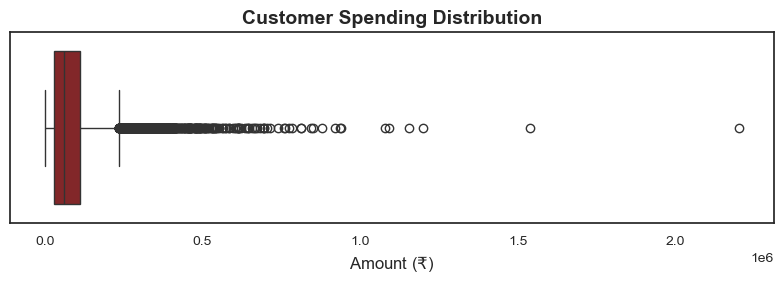

count       9378.00
mean       88397.33
std        96992.18
min           34.21
25%        30693.64
50%        60713.68
75%       112494.24
max      2201660.47
Name: total_spending, dtype: float64

In [8]:
# Display a boxplot of the total spending distribution of customers
spending_df = plot_spending_distribution(conn)
spending_df['total_spending'].astype(float).describe().round(2)

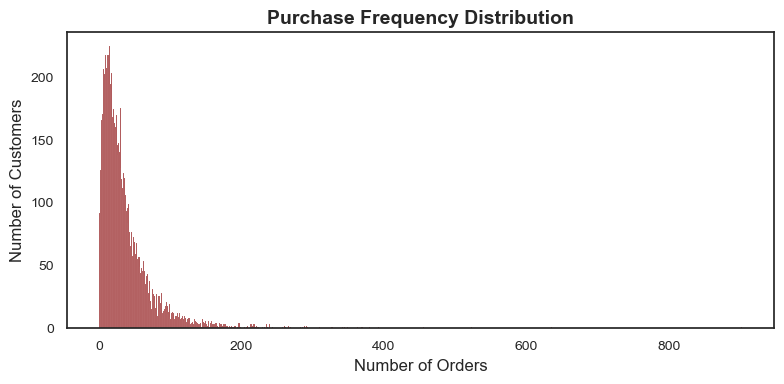

count    9388.00
mean       37.95
std        41.19
min         1.00
25%        13.00
50%        26.00
75%        48.00
max       902.00
Name: num_orders, dtype: float64

In [10]:
# Display a bar chart of the purchase frequency
purchase_frequency_df = plot_purchase_frequency_distribution(conn)
purchase_frequency_df['num_orders'].astype(int).describe().round(2)

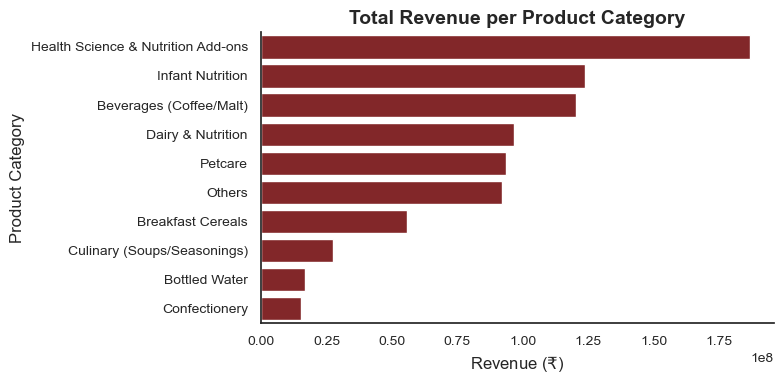

In [16]:
# Display a bar chart of the total revenue per category
plot_revenue_per_category(conn)

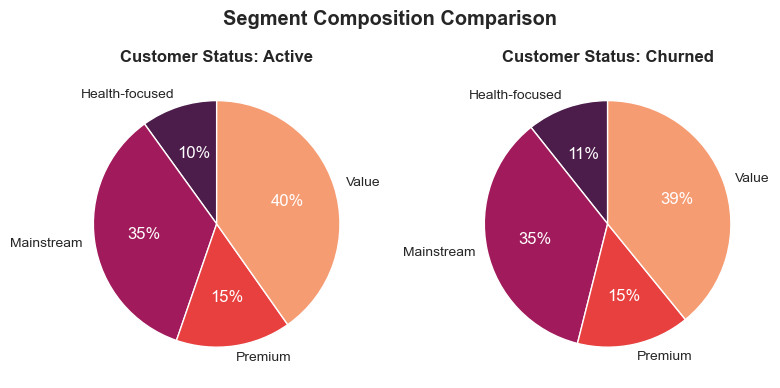

In [17]:
# Display a pie chart of the segment distribution for each status
plot_customer_segments_per_status(conn)

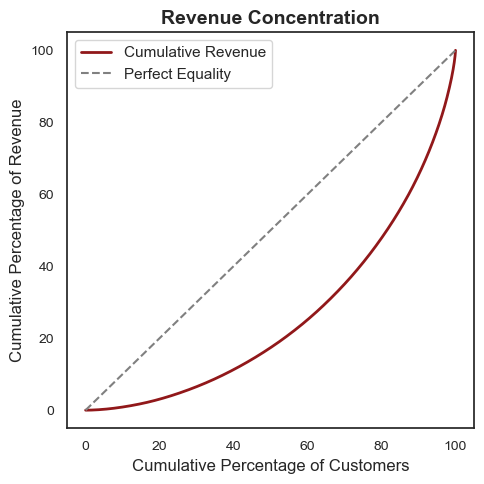

In [18]:
# Display the cumulative revenue curve across customers
plot_revenue_concentration(conn)

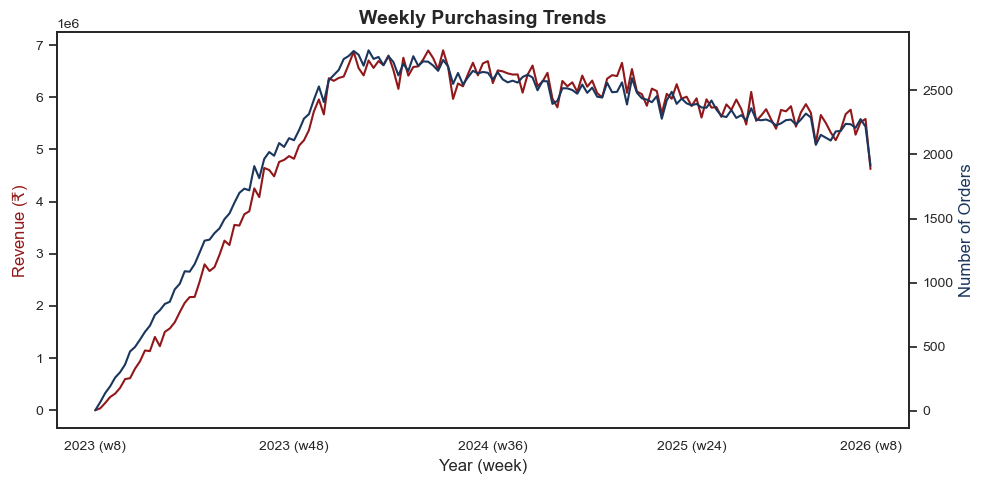

In [3]:
# Display a line chart of weekly trends of revenues and number of orders
plot_time_trends(conn)

In [11]:
# Close the connection to the database
conn.close()
print('\n -> Successfully closed the connection to PostgreSQL database')


 -> Successfully closed the connection to PostgreSQL database


---

## **C - RFM Analysis**

In [2]:
# Open the connection to the database
conn = get_connection(DB_CONFIG)

== POSTGRESQL DATABASE CONNECTION ==
 -> Successfully connected to PostgreSQL database


In [3]:
# Compute the RFM metrics and obtain the customer-level RFM table
rfm_df = get_rfm_customer_table(conn)
rfm_df.to_csv('outputs/rfm_customer_table.csv', index=False)
print('\nTable structure')
print(rfm_df.info())

== RFM ANALYSIS ==
 -> Successfully computed RFM metrics
 -> Successfully computed RFM overall scores

Table structure
<class 'pandas.DataFrame'>
RangeIndex: 9378 entries, 0 to 9377
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   customer_id      9378 non-null   str    
 1   recency          9378 non-null   int64  
 2   frequency        9378 non-null   int64  
 3   monetary         9378 non-null   float64
 4   recency_score    9378 non-null   int64  
 5   frequency_score  9378 non-null   int64  
 6   monetary_score   9378 non-null   int64  
 7   rfm_score        9378 non-null   int64  
dtypes: float64(1), int64(6), str(1)
memory usage: 586.3 KB
None


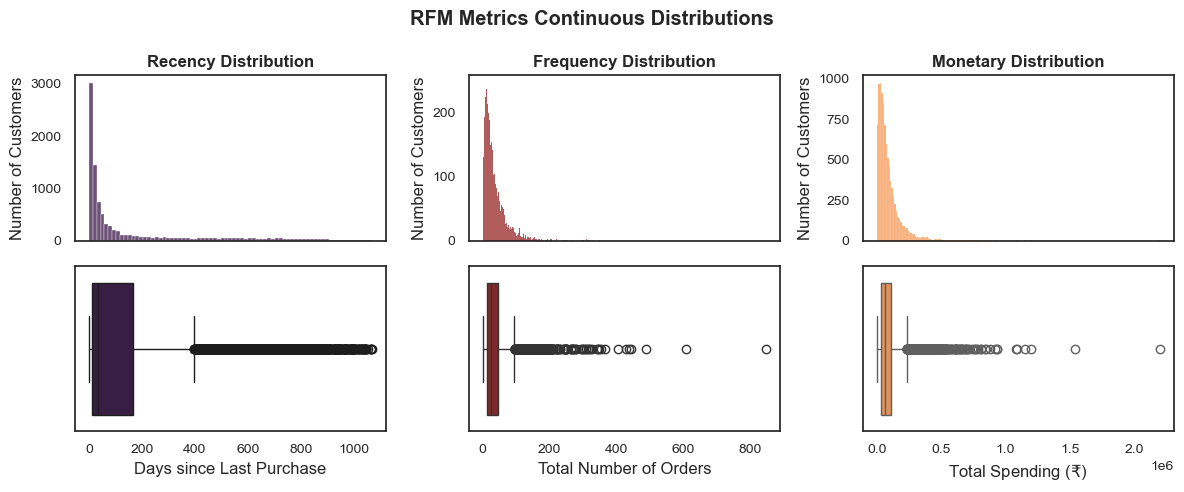

In [23]:
# Display a histogram for the distribution of each continuous RFM metric
plot_continuous_rfm_metrics_distribution(rfm_df)

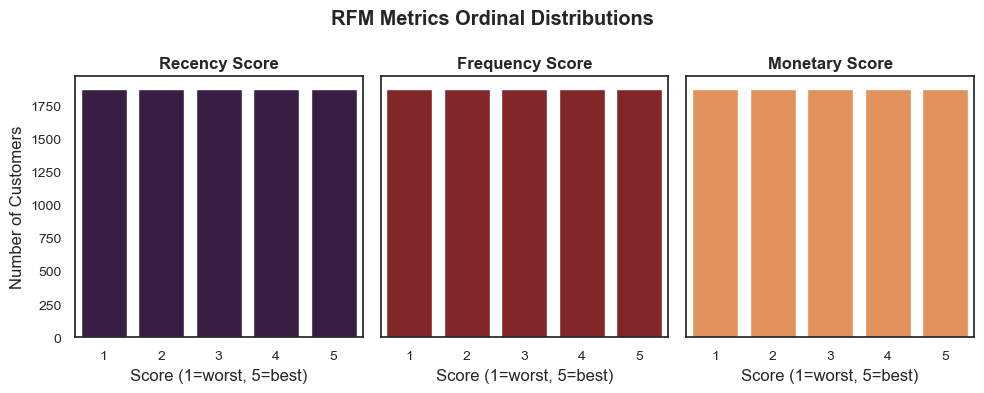

In [24]:
# Display a countplot for the distribution of each ordinal RFM metric
plot_ordinal_rfm_metrics_distribution(rfm_df)

In [4]:
# Compute summary statistics for each metric score level
compute_rfm_statistics_summary(rfm_df)

== SUMMARY STATISTICS FOR METRIC SCORES ==

 -> Recency: Days since Last Purchase


,min,mean,max
recency_score,,,
1,261,577.41,1068
2,56,124.83,261
3,21,34.98,56
4,7,13.50,21
5,0,3.07,7



 -> Frequency: Total Number of Orders


,min,mean,max
frequency_score,,,
1,1,5.97,10
2,10,14.62,19
3,19,24.76,31
4,31,40.01,52
5,52,92.47,846



 -> Monetary: Total Spending (₹)


,min,mean,max
monetary_score,,,
1,34.21,13516.80,25059.08
2,25064.45,36267.17,47760.45
3,47789.71,61301.68,77432.03
4,77446.86,100295.79,129520.81
5,129530.06,230583.77,2201660.47


In [26]:
# Display the top 10 customers ranked by overall RFM score
top10_rfm_df = get_top10_rfm_customer_table(conn, rfm_df)
top10_rfm_df

== TOP 10 CUSTOMERS BY RFM SCORE ==


,customer_id,rfm_score,recency,frequency,monetary,segment,status,city,state
0,CUST000058,555,0,846,2201660.47,Premium,active,Kozhikode,Kerala
1,CUST002744,555,0,607,1538810.93,Value,active,Howrah,West Bengal
2,CUST008575,555,3,488,1199102.46,Premium,churned,Rajkot,Gujarat
3,CUST008014,555,5,437,1156252.93,Premium,active,Hubballi,Karnataka
4,CUST003831,555,0,444,1092418.85,Premium,active,Hyderabad,Telangana
5,CUST002370,555,0,429,1079149.96,Mainstream,churned,Panipat,Haryana
6,CUST008097,555,5,404,937746.24,Value,active,Nashik,Maharashtra
7,CUST006740,555,0,366,935973.45,Value,churned,Kanpur,Uttar Pradesh
8,CUST007473,555,4,349,920531.40,Premium,churned,Mysuru,Karnataka
9,CUST007721,555,2,344,878269.24,Mainstream,active,Panipat,Haryana


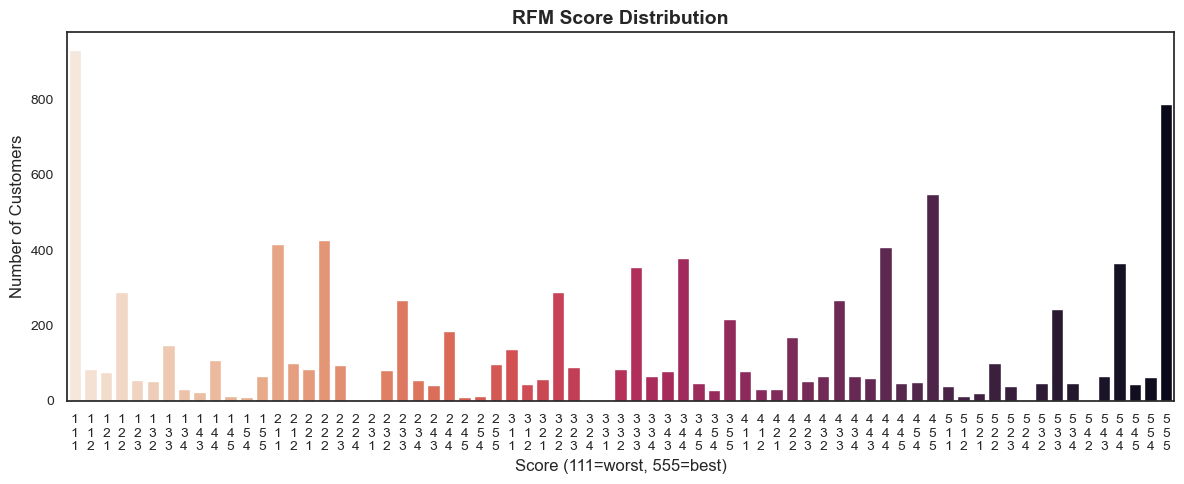

In [27]:
# Compute the number of customer for each RFM score and display the distribution
rfm_distribution_df = compute_rfm_distribution_table(rfm_df)
plot_rfm_score_distribution(rfm_distribution_df)

In [4]:
# Close the connection to the database
conn.close()
print('\n -> Successfully closed the connection to PostgreSQL database')


 -> Successfully closed the connection to PostgreSQL database


---

## **D - Customer Lifetime Value Analysis**

In [5]:
# Open the connection to the database
conn = get_connection(DB_CONFIG)

== POSTGRESQL DATABASE CONNECTION ==
 -> Successfully connected to PostgreSQL database


In [6]:
# Compute the CLV metrics and obtain the customer-level CLV table
clv_df = get_clv_customer_table(conn)
clv_df.to_csv('outputs/clv_customer_table.csv', index=False)

== CLV ANALYSIS ==
 -> Successfully computed CLV metrics and CLV score

== CLV METHODOLOGY ==
 -> Total Customers: 9378
 -> Total Revenue: ₹ 828990161.50
 -> Total Transactions: 333571

 -> APV = Revenue / Transactions: ₹ 2485.20
 -> PF = Transactions / Customers: 35.57
 -> Churn Rate = Churned Customers / Total Customers: 32.45%
 -> CLV = (APV x PF) / Churn Rate: ₹ 272425.29


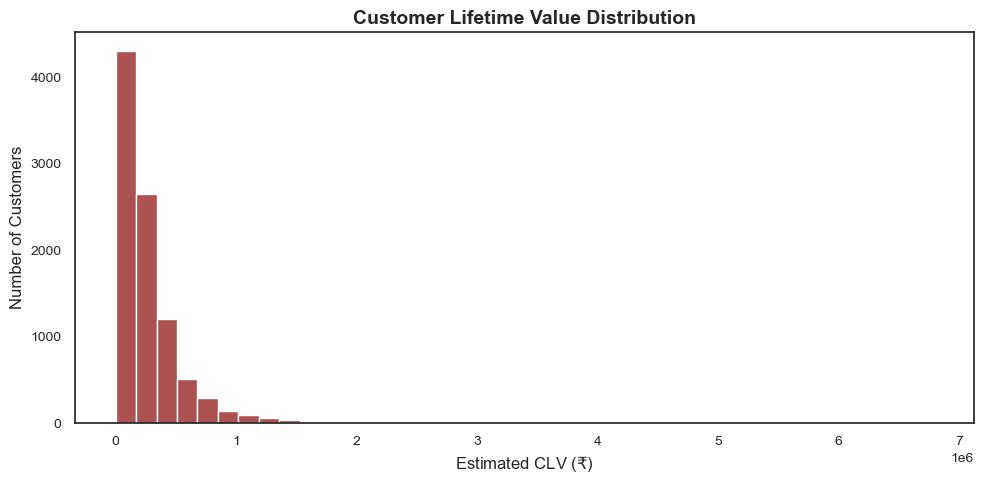

count       9378.00
mean      272425.29
std       298913.13
min          105.43
25%        94592.51
50%       187109.07
75%       346687.82
max      6785137.00
Name: clv, dtype: float64

In [4]:
# Display a histogram for the distribution of customer lifetime value
plot_clv_distribution(clv_df)
clv_df['clv'].describe().round(2)

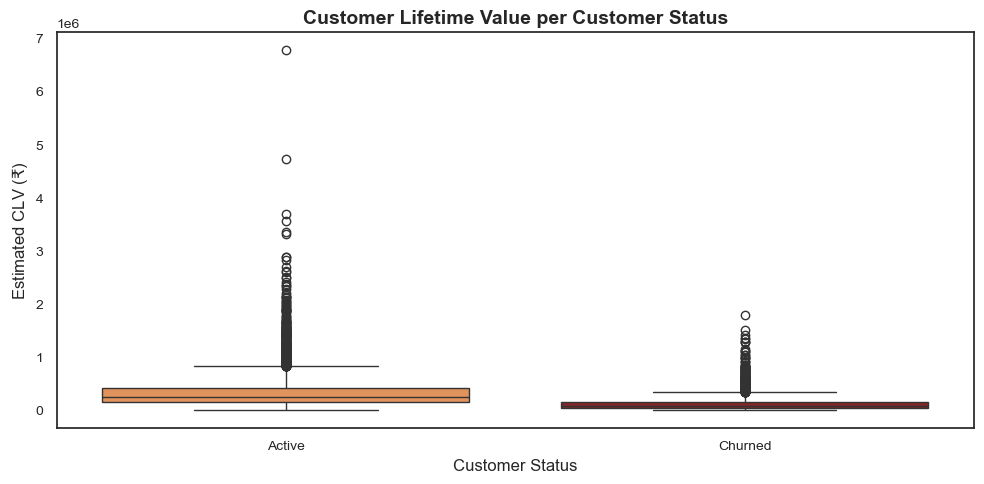

In [5]:
# Display a boxplot for the customer lifetime according to the status
plot_clv_distribution_per_status(clv_df)

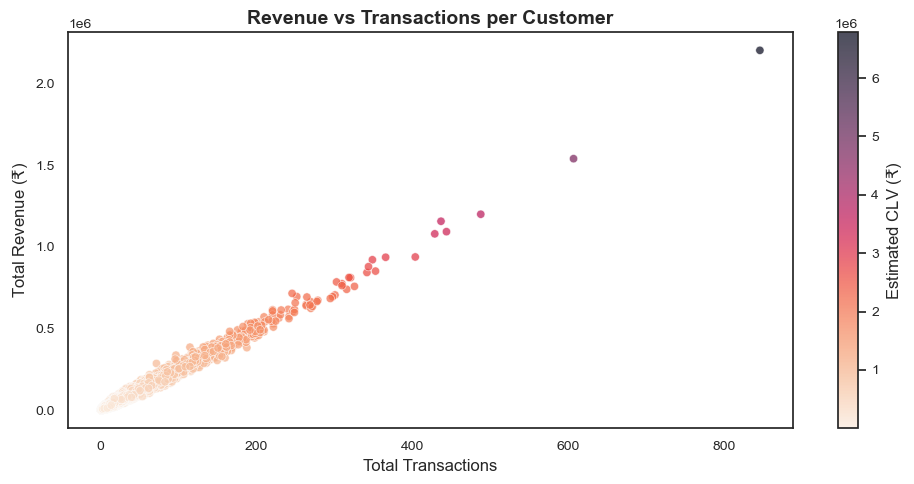

In [6]:
# Display a scatterplot comparing total revenue and transactions, while
plot_revenue_and_transactions(clv_df)

In [7]:
# Display the top 20 customers ranked by overall CLV
top20_clv_df = get_top20_clv_customer_table(conn, clv_df)
top20_clv_df

== TOP 20 CUSTOMERS BY CLV ==


,customer_id,clv,apv,pf,segment,customer_status,city,state
0,CUST000058,6785137.00,2602.44,846,Premium,Active,Kozhikode,Kerala
1,CUST002744,4742349.29,2535.11,607,Value,Active,Howrah,West Bengal
2,CUST008575,3695426.51,2457.18,488,Premium,Active,Rajkot,Gujarat
3,CUST008014,3563371.67,2645.89,437,Premium,Active,Hubballi,Karnataka
4,CUST003831,3366646.06,2460.40,444,Premium,Active,Hyderabad,Telangana
5,CUST002370,3325753.64,2515.50,429,Mainstream,Active,Panipat,Haryana
6,CUST008097,2889971.82,2321.15,404,Value,Active,Nashik,Maharashtra
7,CUST006740,2884508.38,2557.30,366,Value,Active,Kanpur,Uttar Pradesh
8,CUST007473,2836918.66,2637.63,349,Premium,Active,Mysuru,Karnataka
9,CUST007721,2706673.98,2553.11,344,Mainstream,Active,Panipat,Haryana


In [7]:
# Close the connection to the database
conn.close()
print('\n -> Successfully closed the connection to PostgreSQL database')


 -> Successfully closed the connection to PostgreSQL database


---

## **E - Predictive CLV Models**

In [2]:
# Open the connection to the database
conn = get_connection(DB_CONFIG)

== POSTGRESQL DATABASE CONNECTION ==
 -> Successfully connected to PostgreSQL database


In [3]:
# Extract a summary record for each order
transactions_df = extract_transactions_data(conn)

In [4]:
# Split transactions into calibration (75%) and holdout (25%) periods
calibration_holdout_df = split_calibration_holdout_df(transactions_df)

== CALIBRATION AND HOLDOUT SPLIT ==
 -> Observation window: 1091 days
 -> Calibration period (75%): from 2023-02-26 to 2025-05-24
 -> Holdout period (25%): from 2025-05-25 to 2026-02-21


In [5]:
# Train the BG/NBD model and the Gamma-Gamma model
bgf, ggf = train_predictive_models(calibration_holdout_df)

== PREDICTIVE MODELS TRAINING ==
 -> BG/NBD Model
   Parameters: r=1.4735, α=34.5695, a=0.0395, b=1.1248

 -> Gamma-Gamma Model
   Pearson correlation coefficient between frequency and monetary: 0.0467
   Parameters: p=3.0678, q=0.1896, v=3.0442


In [6]:
# Evaluate model performance (RMSE, MAE, R-squared) on the holdout period
metrics = evaluate_predictive_models(calibration_holdout_df, bgf, ggf)

== PREDICTIVE MODELS EVALUATION ==
 -> BG/NBD Model
   RMSE: 4.7642
   MAE: 3.0899
   R^2: 0.8011

 -> Gamma-Gamma Model
     Mean actual spending: ₹ 2503.15
     Mean predicted spending: ₹ 2615.18

 -> Combined Performance
   RMSE: 15487.6722
   MAE: 10399.5861
   R^2: 0.6939


In [7]:
# Compute predicted CLV, expected number of purchases and monetary value, 
# and probability of being active for each customer over a 6-month window
clv_prediction_df = predict_clv_customer_table(transactions_df, bgf, ggf)
clv_prediction_df.to_csv(
    'outputs/clv_prediction_customer_table.csv', index=False)

== CLV PREDICTION TABLE (6 MONTHS HORIZON) ==
 -> Successfully computed the predicted CLV customer table

== TOP 10 CUSTOMERS BY PREDICTED CLV (6 MONTHS HORIZON) ==


,customer_id,frequency,recency,T,monetary_value,expected_frequency,p_alive,expected_average_monetary,predicted_clv
0,CUST000058,579,1013,1013,3783.93,99.41,0.9999,3785.66,363528.96
1,CUST002744,436,913,913,3520.86,82.80,0.9999,3523.00,281774.68
2,CUST003831,369,925,925,2948.43,69.24,0.9999,2950.55,197352.30
3,CUST006740,289,773,773,3153.27,64.47,0.9999,3156.16,196546.84
4,CUST008575,384,1022,1025,3100.59,65.26,0.9997,3102.73,195576.32
5,CUST008014,347,1030,1035,3329.79,58.43,0.9994,3332.33,188065.29
6,CUST002370,359,1038,1038,3002.42,60.30,0.9999,3004.64,175004.27
7,CUST002154,264,770,772,3063.57,58.98,0.9997,3066.65,174724.76
8,CUST004846,293,805,805,2868.93,62.88,0.9999,2871.53,174399.89
9,CUST008097,322,941,946,2881.87,59.14,0.9994,2884.25,164759.43


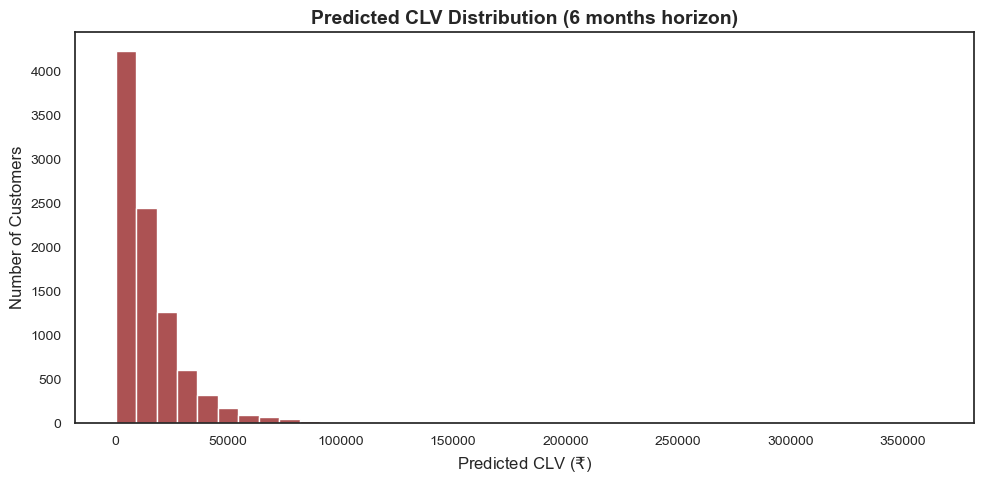

count      9378.00
mean      14964.96
std       17724.17
min           0.00
25%        3633.48
50%       10497.28
75%       20154.74
max      363528.96
Name: predicted_clv, dtype: float64

In [8]:
# Display a histogram for the distribution of predicted CLV
plot_predicted_clv_distribution(clv_prediction_df)
clv_prediction_df['predicted_clv'].describe().round(2)

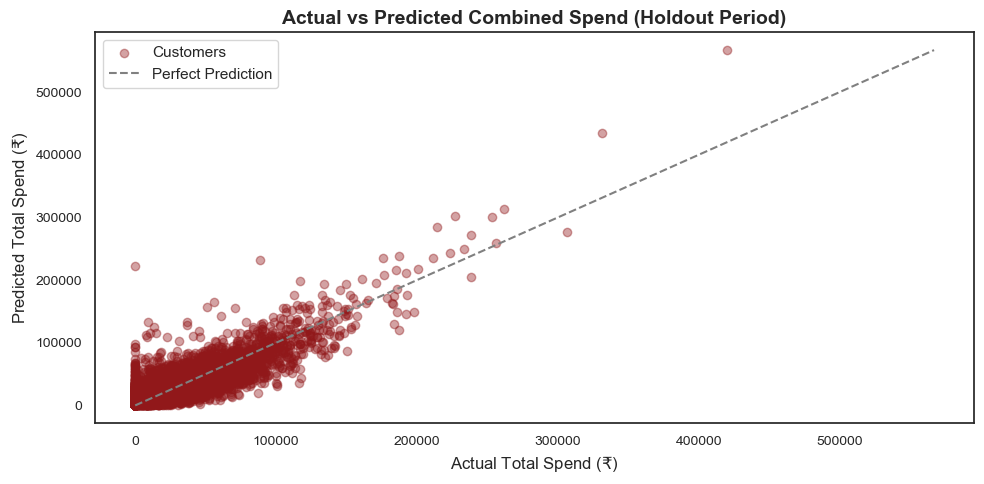

In [9]:
# Display a scatterplot of actual vs predicted spend in the holdout period
plot_actual_and_predicted_spend(calibration_holdout_df, bgf, ggf)

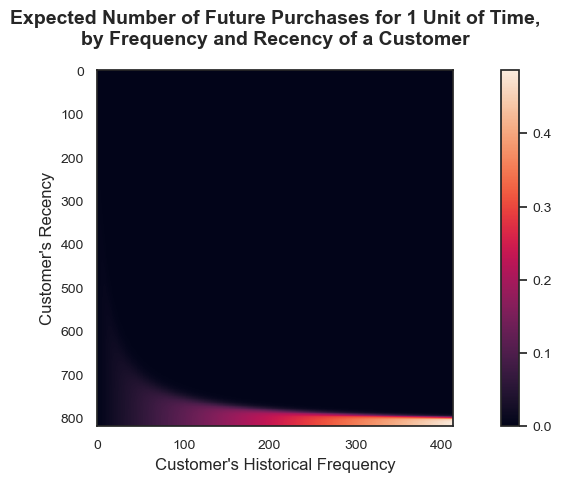

In [10]:
# Display the frequency-recency matrix as a heatmap
plot_frequency_recency(bgf)

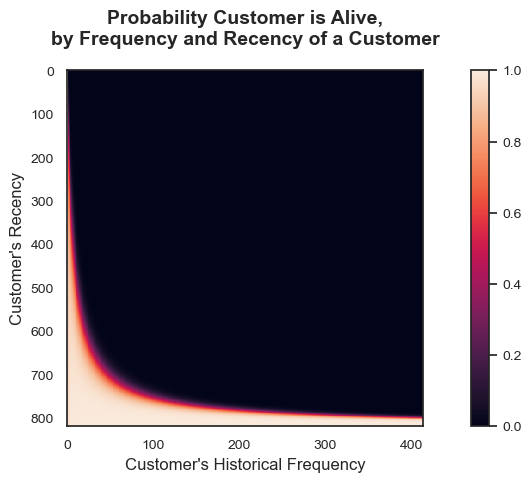

In [11]:
# Display the probability alive matrix as a heatmap
plot_probability_alive(bgf)

In [9]:
# Close the connection to the database
conn.close()
print('\n -> Successfully closed the connection to PostgreSQL database')


 -> Successfully closed the connection to PostgreSQL database


---

## **F - Customer Segmentation**

In [2]:
# Open the connection to the database
conn = get_connection(DB_CONFIG)

== POSTGRESQL DATABASE CONNECTION ==
 -> Successfully connected to PostgreSQL database


In [3]:
# Retrieve clv_prediction_df from part E 
clv_prediction_df = pd.read_csv('outputs/clv_prediction_customer_table.csv')

# Assign customers to segments and compute segment summary table
segmented_df = assign_segment(clv_prediction_df)
enriched_df = extract_customer_information(conn, segmented_df)
segment_summary_df = get_segment_summary(enriched_df)

== CUSTOMER SEGMENTATION ==
 -> Successfully assigned customers to segments: Bronze, Silver, Gold, and Platinum
 -> Successfully extracted additional customer information

 == SEGMENT SUMMARY TABLE ==


,customer_segment,num_customers,avg_spending,avg_purchase_frequency,avg_prob_alive,top_category,top_city,top_state,top_customer_type
0,Bronze,1876,2280.81,16.18,0.18,Beverages (Coffee/Malt),Hyderabad,Telangana,Value
1,Silver,2813,2466.44,13.32,0.94,Beverages (Coffee/Malt),Kochi,Kerala,Value
2,Gold,2813,2631.93,31.57,0.99,Beverages (Coffee/Malt),Hyderabad,Karnataka,Value
3,Platinum,1876,2673.33,82.00,1.00,Beverages (Coffee/Malt),Dibrugarh,Assam,Mainstream


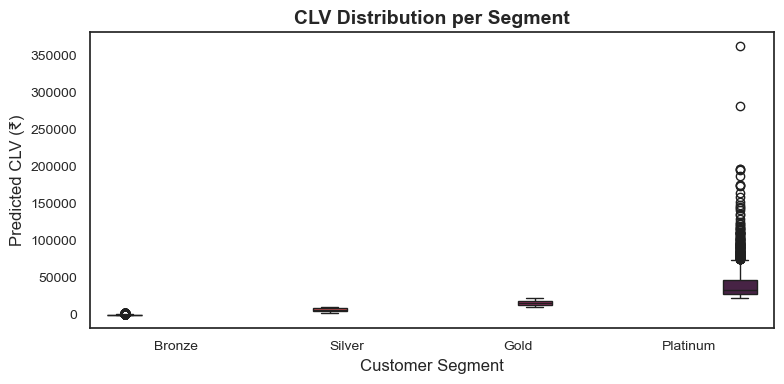

In [4]:
# Display a boxplot for the CLV distribution of each segment
plot_segment_clv_distribution(segmented_df)

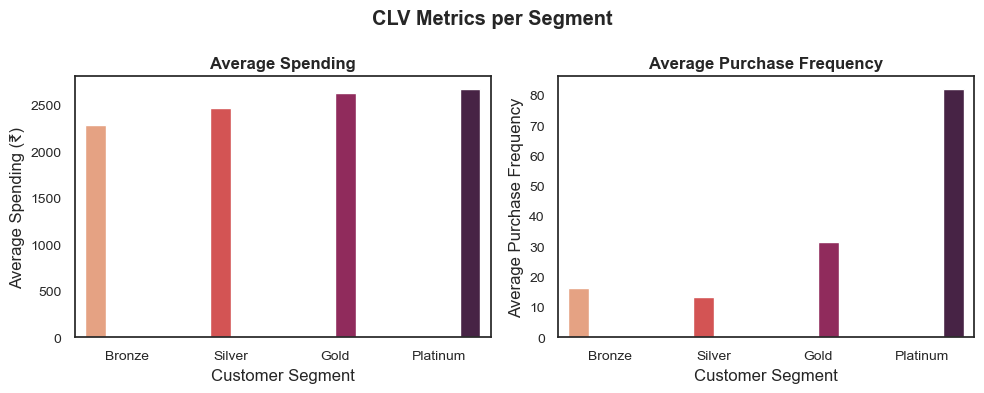

In [5]:
# Display a bar chart for average spending and purchase frequency of each segment
plot_segment_clv_metrics(segment_summary_df)

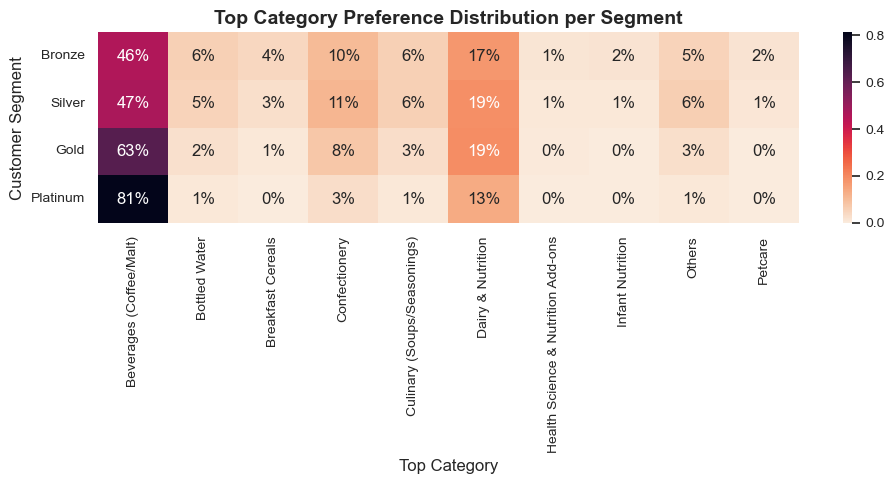

In [6]:
# Display a heatmap of category preferences for each segment
plot_segment_top_categories(enriched_df)

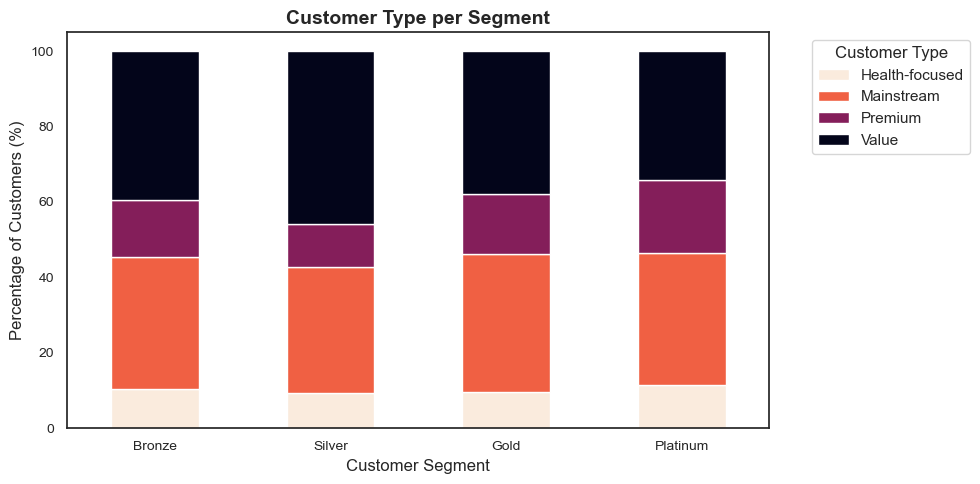

In [7]:
# Display a bar chart of customer types for each segment
plot_segment_customer_type(enriched_df)

In [8]:
# Close the connection to the database
conn.close()
print('\n -> Successfully closed the connection to PostgreSQL database')


 -> Successfully closed the connection to PostgreSQL database
